###Μηχανική Μάθηση
####1η ατομική εργασία
ΣΗΜΜΥ- ΕΜΠ -Ακ. Έτος 2026-27



 `⚠️  Το σύνολο δεδομένων που σας δόθηκε δεν πρέπει να εμπλουτισθεί με οποιοδήποτε τρόπο. Η εργασία στην οποία θα χρησιμοποιηθεί εμπλουτισμένο σύνολο δεδομένων, δεν θα διορθωθεί.`

Ονοματεπώνυμο φοιτητή: Άγγελος Καμαριάδης

### 1. Εισαγωγή συνόλου δεδομένων

Tο σύνολο δεδομένων για το training-validation μπορείτε να το κατεβάσετε από [εδώ](https://drive.google.com/file/d/1PRxhsDEF6em2Ut095c790CbBmuDdSgr5/view?usp=sharing).


1.α. Φορτώστε το σύνολο δεδομένων "train-val.csv"  στο notebook σας.

In [1]:
import pandas as pd
df = pd.read_csv('train-val.csv')
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2009-03-22,Albury,14.6,30.0,0.0,NaN,NaN,NE,37.0,E,...,56.0,30.0,1014.8,1012.7,3.0,1.0,18.1,29.0,No,No
1,2009-04-15,Albury,10.7,21.9,0.0,NaN,NaN,W,63.0,NW,...,44.0,27.0,1008.2,1009.8,2.0,NaN,20.5,18.9,No,No
2,2009-04-21,Albury,5.7,21.4,0.0,NaN,NaN,ESE,17.0,ENE,...,68.0,39.0,1025.2,1020.9,NaN,NaN,12.2,20.9,No,No
3,2009-04-24,Albury,10.6,16.2,0.0,NaN,NaN,WNW,39.0,ESE,...,74.0,86.0,1008.9,1002.4,8.0,8.0,14.9,15.1,No,Yes
4,2009-05-19,Albury,3.7,19.1,0.0,NaN,NaN,SSE,19.0,NaN,...,87.0,51.0,1023.6,1019.9,NaN,NaN,7.4,18.9,No,No


### 2. Διερευνητική ανάλυση δεδομένων -Exploratory Data Analysis (EDA)
Χρησιμοποιήστε code cells  με τις κατάλληλες τεχνικές EDA για την κατανόηση του συνόλου δεδομένων και text cells για επεξήγηση των αποτελεσμάτων.

Χρησιμοποιώντας τις κατάλληλες μεθόδους παρουσιάστε με χρήση κώδικα πληροφορίες για τα εξής:

2α. το πλήθος των δειγμάτων και των χαρακτηριστικών του συνόλου δεδομένων,

2β. το είδος των χαρακτηριστικών του συνόλου δεδομένων,  

2γ. τις ετικέτες των χαρακτηριστικών,

2δ. το πλήθος των κατηγοριών,

2ε. πόσα δείγματα ανήκουν σε κάθε κατηγορία,

2στ. τη συσχέτιση μεταξύ των δεδομένων,

2ζ. οποιαδήποτε άλλη πληροφορία πιστεύετε ότι είναι χρήσιμη για την κατανόηση του συνόλου δεδομένων.

In [2]:
# 2α -> #{samples and characteristics}
samples, features = df.shape
print(f"Πλήθος δειγμάτων: {samples}")
print(f"Πλήθος χαρακτηριστικών: {features}")

Πλήθος δειγμάτων: 10000
Πλήθος χαρακτηριστικών: 23


Στο μέρος 2α υπολογίστηκαν οι διαστάσεις του αρχείου train-val.csv μέσω της εντολής df.shape, η οποία επιστρέφει μια πλειάδα της μορφής (γραμμές, στήλες). Από την εκτέλεση του κώδικα προκύπτει ότι το σύνολο δεδομένων περιλαμβάνει 10000 δείγματα και συνολικά 23 στήλες. Από τις στήλες αυτές, οι 22 αποτελούν τα χαρακτηριστικά εισόδου και η 1 αντιστοιχεί στην ετικέτα στόχο RainTomorrow, που καλούνται να προβλέψουν οι ταξινομητές.

In [3]:
# 2β -> Data Types
print(df.dtypes)

Date              object
Location          object
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir       object
WindGustSpeed    float64
WindDir9am        object
WindDir3pm        object
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday         object
RainTomorrow      object
dtype: object


Στο μέρος 2β εξετάστηκε το είδος των χαρακτηριστικών του συνόλου δεδομένων μέσω της ιδιότητας df.dtypes. Από το αποτέλεσμα προκύπτει ότι οι 23 στήλες του συνόλου δεδομένων χωρίζονται σε δύο βασικούς τύπους. 16 αριθμητικά χαρακτηριστικά συνεχών τιμών τύπου κινητής υποδιαστολής (float64), τα οποία αφορούν μετεωρολογικές μετρήσεις όπως θερμοκρασία, βροχόπτωση, ηλιοφάνεια, ταχύτητα ανέμου, υγρασία, ατμοσφαιρική πίεση και νεφοκάλυψη, και 7 χαρακτηριστικά τύπου object (συμβολοσειρές/κατηγορικές μεταβλητές). Τα χαρακτηριστικά τύπου object περιλαμβάνουν την ημερομηνία (Date), την τοποθεσία (Location), τις διευθύνσεις του ανέμου (WindGustDir, WindDir9am, WindDir3pm), τη δυαδική ένδειξη βροχόπτωσης της τρέχουσας ημέρας (RainToday) καθώς και τη μεταβλητή στόχο RainTomorrow, η οποία θα πρέπει μαζί με τις υπόλοιπες κατηγορικές μεταβλητές να κωδικοποιηθεί κατάλληλα σε αριθμητική μορφή κατά το στάδιο της προεπεξεργασίας.

In [4]:
# 2γ -> Column Labels
print(df.columns.tolist())

['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']


Στο μέρος 2γ παρουσιάστηκαν οι ετικέτες, δηλαδή τα ονόματα των χαρακτηριστικών του συνόλου δεδομένων μέσω της ιδιότητας df.columns.tolist(). Μέσω της εκτέλεσης του κώδικα, εκτυπώνεται η λίστα με τις συνολικά 23 στήλες του πίνακα οι οποίες περιλαμβάνουν τα μετεωρολογικά χαρακτηριστικά εισόδου όπως Date, Location, MinTemp, MaxTemp, Rainfall, Evaporation, Sunshine, WindGustDir, WindGustSpeed, WindDir9am, WindDir3pm, WindSpeed9am, WindSpeed3pm, Humidity9am, Humidity3pm, Pressure9am, Pressure3pm, Cloud9am, Cloud3pm, Temp9am, Temp3pm, RainToday καθώς και τη μεταβλητή στόχο RainTomorrow.

In [5]:
# 2δ -> #{categories}
unique_count = df['RainTomorrow'].nunique()
unique_vals = df['RainTomorrow'].unique()
print(f"Πλήθος κατηγοριών: {unique_count}")
print(f"Μοναδικές κατηγορίες: {unique_vals}")

Πλήθος κατηγοριών: 2
Μοναδικές κατηγορίες: ['No' 'Yes' nan]


Στο μέρος 2δ προσδιορίστηκε το πλήθος και το είδος των κατηγοριών της μεταβλητής στόχου RainTomorrow μέσω των μεθόδων .nunique() και .unique(). Από την εκτέλεση του κώδικα, προκύπτει ότι η μεταβλητή είναι δυαδική και περιλαμβάνει 2 διακριτές κλάσεις, τις τιμές ['No', 'Yes'], καθώς και την ύπαρξη ελλιπών τιμών (nan), οι οποίες θα πρέπει να αντιμετωπιστούν κατάλληλα στα επόμενα στάδια της προεπεξεργασίας πριν την εκπαίδευση των ταξινομητών.

In [6]:
# 2ε -> #{samples per class} and their percentages
print("Απόλυτες συχνότητες")
print(df['RainTomorrow'].value_counts(dropna=False))
print("\n Σχετικές συχνότητες (%)")
print(df['RainTomorrow'].value_counts(normalize=True, dropna=False) * 100)

Απόλυτες συχνότητες
RainTomorrow
No     7483
Yes    2317
NaN     200
Name: count, dtype: int64

 Σχετικές συχνότητες (%)
RainTomorrow
No     74.83
Yes    23.17
NaN     2.00
Name: proportion, dtype: float64


Στο μέρος 2ε υπολογίστηκε η κατανομή των δειγμάτων ανά κατηγορία για τη μεταβλητή στόχο RainTomorrow μέσω της μεθόδου .value_counts(dropna=False). Από τα αποτελέσματα προκύπτει ότι το σύνολο δεδομένων παρουσιάζει εμφανή class imbalance, καθώς 7.483 δείγματα τα οποία αντιστοιχούν σε ποσοστό 74,83% αντιστοιχούν σε απουσία βροχής (No), 2.317 δείγματα τα οποία αντιστοιχούν ποσοστό 23,17% σε εμφάνιση βροχής (Yes), ενώ υπάρχουν και 200 ελλιπείς τιμές (NaN) οι οποίες αντιστοιχούν σε ποσοστό 2,00%. Αυτές οι NaN τιμές, θα πρέπει να διαχειριστούν κατάλληλα στο στάδιο της προεπεξεργασίας.

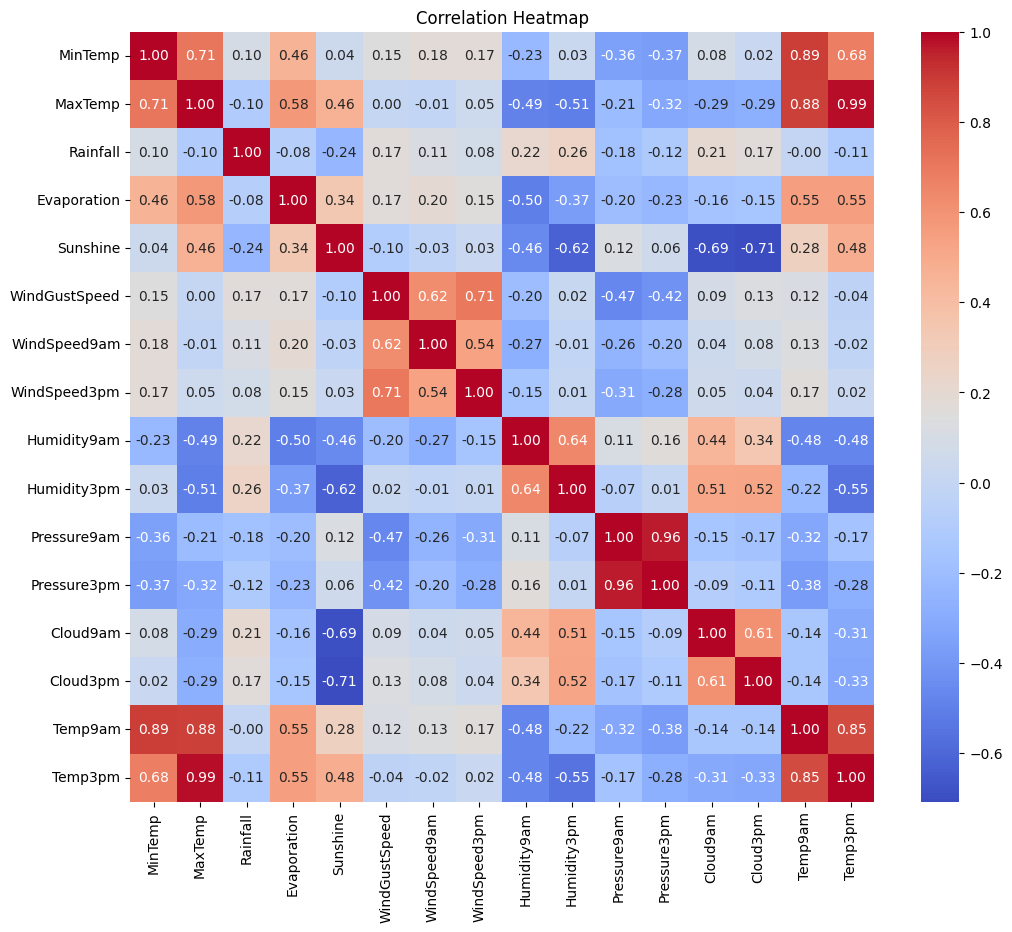

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2στ -> Correlation matrix and heatmap
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Στο μέρος 2στ υπολογίστηκε και οπτικοποιήθηκε ο πίνακας συσχέτισης των αριθμητικών χαρακτηριστικών του συνόλου δεδομένων μέσω ενός Heatmap. Αρχικά, χρησιμοποιήθηκε η μέθοδος df.corr(numeric_only=True) για τον υπολογισμό των συντελεστών γραμμικής συσχέτισης Pearson μεταξύ των αριθμητικών στηλών, ενώ στη συνέχεια σχεδιάστηκε το Heatmap με τη χρήση της βιβλιοθήκης seaborn και ειδικότερα, με τη χρήση της εντολής sns.heatmap. Από την ανάλυση του θερμικού χάρτη προκύπτουν σημαντικά συμπεράσματα για τις σχέσεις μεταξύ των μεταβλητών. Πρώτον, οι κόκκινες αποχρώσεις που αντιστοιχούν σε ισχυρές θετικές συσχέτισεις, παρατηρούνται μεταξύ θερμοκρασιών, καθώς και μεταξύ των μετρήσεων πίεσης Pressure9am και Pressure3pm. Δεύτερον, οι μπλε αποχρώσεις που αντιστοιχούν σε ισχυρές αρνητικές συσχέτισεις εντοπίζονται κυρίως μεταξύ της ηλιοφάνειας (Sunshine) και της νεφοκάλυψης (Cloud9am και Cloud3pm με τιμές γύρω στο -0,69 και -0,71 αντίστοιχα), κάτι απόλυτα αναμενόμενο μετεωρολογικά, καθώς η αυξημένη νέφωση περιορίζει την ηλιοφάνεια. Αυτή η πληροφορία είναι πολύτιμη, διότι βοηθά στον εντοπισμό τυχόν πολυσυγγραμμικότητας ανάμεσα στα χαρακτηριστικά. Δηλαδή, θα μας βοηθήσει να καταλάβουμε ποια χαρακτηριστικά είναι σε μεγάλο βαθμό συσχετιζόμενα μεταξύ τους και ως εκ τούτου, παρέχουν την ίδια σχεδόν πληροφορία.

In [8]:
# 2ζ (1) -> Missing values per column (absolute & percentage)
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage (%)': missing_percentage
})

display(missing_df)

,Missing Values,Percentage (%)
Date,0,0.00
Location,0,0.00
MinTemp,101,1.01
MaxTemp,69,0.69
Rainfall,219,2.19
Evaporation,4337,43.37
Sunshine,4825,48.25
WindGustDir,748,7.48
WindGustSpeed,744,7.44
WindDir9am,795,7.95


Στο μέρος 2ζ (1) υπολογίστηκαν οι NaN τιμές ανά στήλη στο σύνολο δεδομένων, τόσο σε απόλυτο πλήθος όσο και σε ποσοστό επί τοις εκατό. Συγκεκριμένα, χρησιμοποιήθηκε η μέθοδος df.isnull().sum() για τον εντοπισμό των κενών τιμών ανά χαρακτηριστικό και υπολογίστηκε το αντίστοιχο ποσοστό επί του συνολικού πλήθους των δειγμάτων (len(df)). Τα αποτελέσματα οργανώθηκαν και παρουσιάστηκαν σε έναν ενιαίο πίνακα (pandas DataFrame με ονομασία missing_df) μέσω της εντολής display(), ώστε να είναι ευανάγνωστα, και ούτως ώστε να διευκολυνθεί ο σχεδιασμός της κατάλληλης στρατηγικής διαχείρισης (imputation) στα επόμενα στάδια του preprocessing.

In [9]:
# 2ζ (2) -> Descriptive statistics of numerical columns
descriptive_stats = df.describe()
display(descriptive_stats)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,9899.000000,9931.000000,9781.000000,5663.000000,5175.000000,9256.000000,9883.000000,9789.000000,9811.000000,9689.000000,8973.000000,8970.000000,6155.000000,5950.000000,9875.000000,9747.000000
mean,10.689120,21.519776,2.206656,4.628289,7.188831,39.153306,13.697865,18.249974,70.433289,52.781711,1018.861785,1016.345173,4.450041,4.549916,15.485610,20.115872
std,6.007661,6.553448,7.526514,3.502559,3.561263,13.819393,8.906232,8.912858,18.822404,20.200040,7.042546,7.005967,2.899727,2.700263,6.092834,6.411198
min,-6.800000,-1.900000,0.000000,0.000000,0.000000,7.000000,0.000000,0.000000,1.000000,1.000000,983.900000,978.200000,0.000000,0.000000,-5.900000,-5.100000
25%,6.500000,16.800000,0.000000,2.200000,4.500000,30.000000,7.000000,11.000000,58.000000,39.000000,1014.500000,1011.800000,1.000000,2.000000,11.200000,15.500000
50%,10.400000,20.800000,0.000000,4.000000,8.000000,37.000000,13.000000,17.000000,71.000000,53.000000,1019.000000,1016.400000,5.000000,5.000000,15.000000,19.400000
75%,14.700000,25.900000,0.800000,6.200000,10.200000,46.000000,19.000000,24.000000,85.000000,66.000000,1023.700000,1021.200000,7.000000,7.000000,19.500000,24.300000
max,30.300000,44.900000,183.400000,55.600000,13.700000,109.000000,67.000000,65.000000,100.000000,100.000000,1040.400000,1038.900000,8.000000,8.000000,35.900000,41.600000


Στο μέρος 2ζ (2) υπολογίστηκαν και παρουσιάστηκαν τα περιγραφικά στατιστικά μέτρα των αριθμητικών χαρακτηριστικών του συνόλου δεδομένων μέσω της μεθόδου df.describe(). Η εκτέλεση του κώδικα και η χρήση της συνάρτησης display(), εμφανίζουν έναν περιεκτικό πίνακα με βασικές στατιστικές μετρικές ανά αριθμητική στήλη, όπως το πλήθος των έγκυρων μετρήσεων, τη μέση τιμή, την τυπική απόκλιση, την ελάχιστη τιμή, τα ποσοστημόρια (25%, 50% / διάμεσος, 75%) και τη μέγιστη τιμή. Τα στοιχεία αυτά είναι χρήσιμα για την εποπτεία της κατανομής των τιμών, τον εντοπισμό πιθανών ακραίων τιμών (outliers) και τον καθορισμό των κατάλληλων μεθόδων κλιμάκωσης και προεπεξεργασίας.   

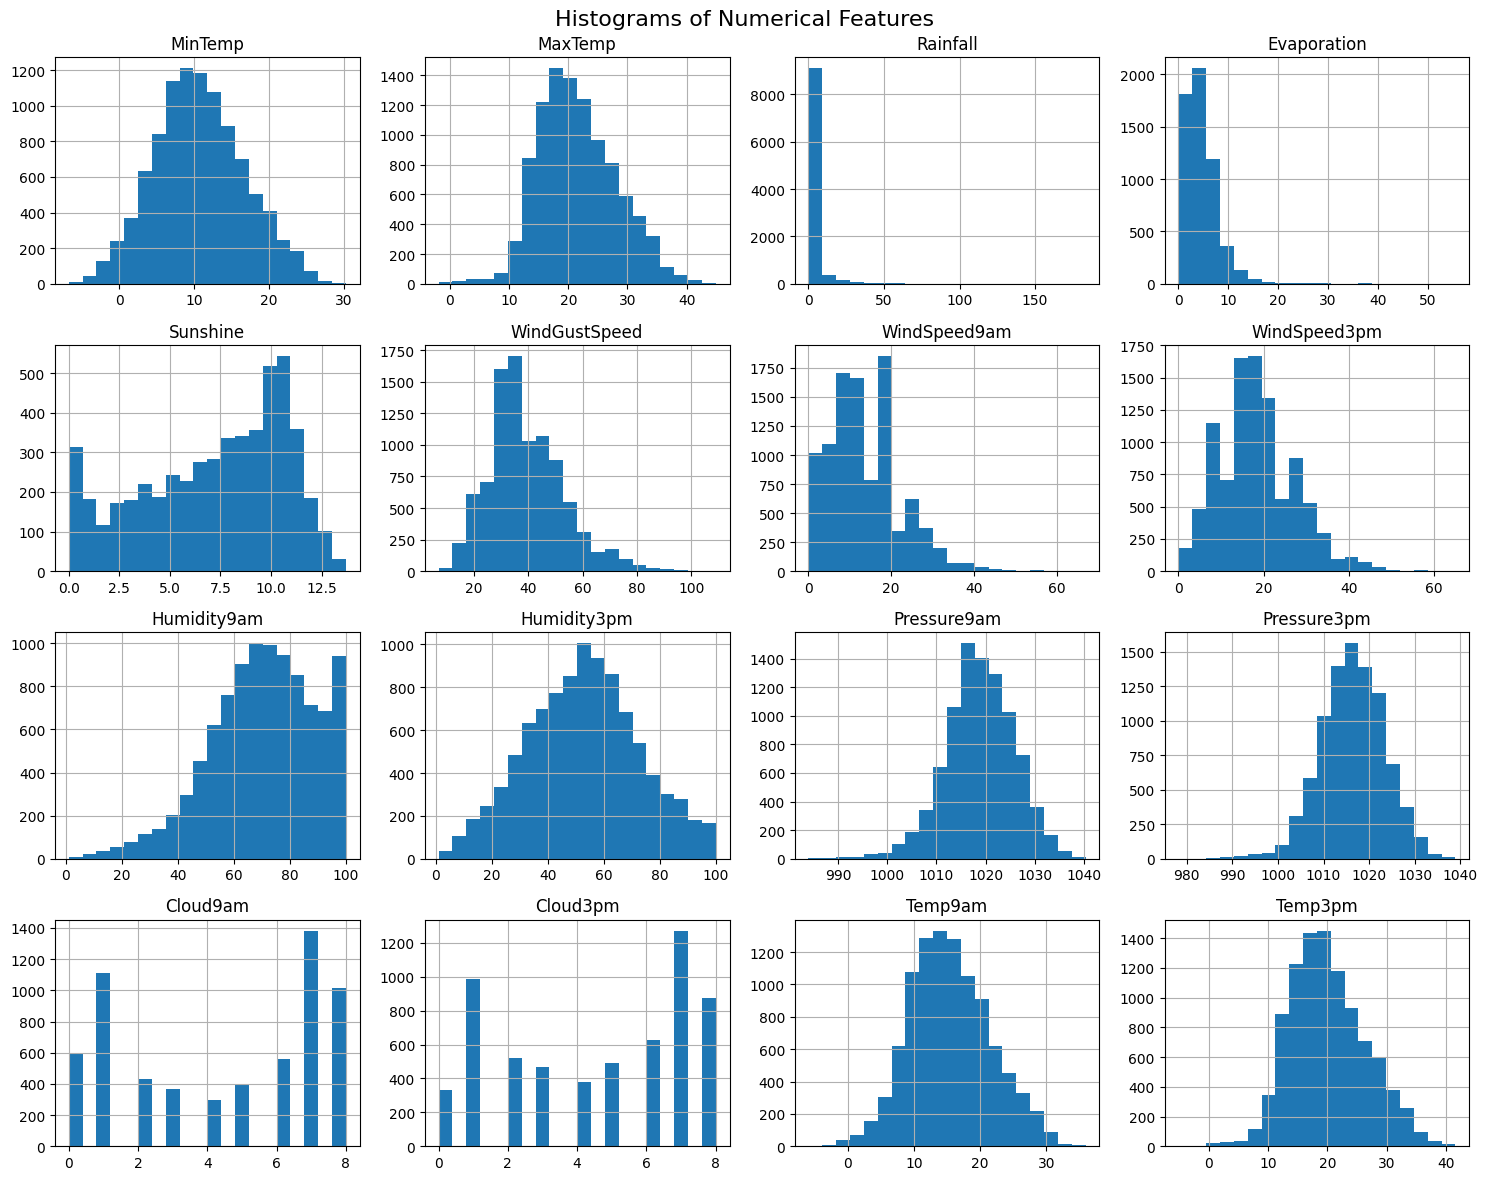

In [10]:
# 2ζ (3) -> Histograms of numerical columns
import matplotlib.pyplot as plt

df.hist(figsize=(15, 12), bins=20)
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

Στο τελευταίο μέρος του 2ζ (3), δημιουργήθηκαν και οπτικοποιήθηκαν τα ιστογράμματα για όλα τα αριθμητικά χαρακτηριστικά του συνόλου δεδομένων μέσω της μεθόδου df.hist() της βιβλιοθήκης pandas σε συνδυασμό με το matplotlib. Η εκτέλεση του κώδικα παράγει ένα πλέγμα γραφημάτων, όπου κάθε γράφημα καλούμε ιστόγραμμα. Τα ιστογράμματα αυτά, είναι χρήσιμα καθώς επιτρέπουν την οπτική αξιολόγηση της κατανομής των τιμών κάθε αριθμητικής μεταβλητής. Για πράδειγμα, εάν είναι κανονική, ασύμμετρη ή αν υπάρχουν outliers. βοηθώντας καθοριστικά στην επιλογή της κατάλληλης στρατηγικής κλιμάκωσης και προεπεξεργασίας.

### 3. Προεπεξεργασία συνόλου δεδομένων
💡`Χρησιμοποιήστε το Column Transformer για τη δημιουργία και την εφαρμογή χωριστών μετασχηματιστών για αριθμητικά και κατηγορικά δεδομένα.`




3.α.  Θα χρησιμοποιήσετε όλα τα χαρακτηριστικά του συνόλου δεδομένων για την εκπαίδευση των ταξινομητών ή θα επιλέξετε κάποια από αυτά;  Θα κάνετε κάποια συνένωση κάποιων χαρακτηριστικών για δημιουργία νέων χαρακτηριστικών για το μοντέλο σας;


In [11]:
# The month is extracted from the date while the Date is removed
if 'Date' in df.columns:
    df['Month'] = pd.to_datetime(df['Date']).dt.month
    df = df.drop(columns=['Date'])

3.β. Υπάρχουν απουσιάζουσες τιμές; Γράψτε κατάλληλο κώδικα ώστε να χειριστείτε αυτές τις τιμές.

In [12]:
# Removing rows where the target label is missing
df = df.dropna(subset=['RainTomorrow'])
# Define imputers for the Pipeline
from sklearn.impute import SimpleImputer
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

3.γ. Γράψτε κώδικα για την κατάλληλη μετατροπή των κατηγορικών μεταβλητών ώστε να μπορούν να τους διαχειριστούν οι ταξινομητές που θα χρησιμοποιήσετε.

In [13]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

3.δ. Γράψτε κώδικα για την κλιμάκωση των χαρακτηριστικών, αν την θεωρείτε απαραίτητη

In [14]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

3.ε. Εκτελέστε όλα τα προηγούμενα βήμα προεκπαίδευσης (χρήση μετασχηματιστών) ώστε να είναι "καθαρό" το αρχικό σύνολο για να χρησιμοποιηθεί για την εκπαίδευση των ταξινομητών.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

target_col = 'RainTomorrow'
features = [col for col in df.columns if col != target_col]

num_cols = df[features].select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df[features].select_dtypes(include=['object', 'category']).columns.tolist()

num_pipeline = Pipeline(steps=[
    ('imputer', num_imputer),
    ('scaler', scaler)
])

cat_pipeline = Pipeline(steps=[
    ('imputer', cat_imputer),
    ('encoder', encoder)
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

3.στ. Αφού έχετε "καθαρίσει" το αρχικό σύνολο εκπαίδευσης, γράψτε τον κατάλληλο κώδικα ώστε από το αρχικό σύνολο εκπαίδευσης να δημιουργήσετε τα σύνολα Χ και y.

💡 `Η στήλη 'RainTomorrow' είναι η τιμή που θέλουμε να προβλέψει ο ταξινομητής μας.`



In [16]:
X = df.drop(columns=[target_col])
y = df[target_col].map({'No': 0, 'Yes': 1})

3.ζ. Διαχωρίστε το σύνολο δεδομένων σε σύνολο εκπαίδευσης (train set) και σε σύνολο επικύρωσης (validation set) (ο διαχωρισμός να είναι train set 70% και validation set 30%).


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print(f"Train set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")

Train set shape: (6860, 22)
Validation set shape: (2940, 22)


### 4. Εκπαίδευση μοντέλου με default τιμές στις παραμέτρους των ταξινομητών

 **Ορισμός των Ταξινομητών**: Εισάγουμε και αρχικοποιούμε τους 7 αλγορίθμους από το `scikit-learn`:
   * **Naive Bayes** (`GaussianNB`)
   * **K-Nearest Neighbors** (`KNeighborsClassifier`)
   * **Logistic Regression** (`LogisticRegression`)
   * **Multi-Layer Perceptron** (`MLPClassifier` με 1 κρυφό επίπεδο 100 νευρώνων)
   * **Support Vector Classifier** (`SVC`)
   * **Decision Tree** (`DecisionTreeClassifier`)
   * **Random Forest** (`RandomForestClassifier`)



 4.α. Εκπαιδεύστε (fit)  και τους  7 ταξινομητές που προαναφέρθηκαν (εμφανίστε τα δείγματα από το train set μαζί με την ετικέτα τους στην είσοδο του κάθε ταξινομητή), χρησιμοποιώντας τις default τιμές για όλες τις παραμέτρους τους.





Για να εκπαιδεύσουμε τους ταξινομητές με τις προεπιλεγμένες (default) παραμέτρους τους αποφεύγοντας το **data leakage**, ακολουθούμε τα εξής βήματα:


* **Δημιουργία Pipelines**: Συνδέουμε τον προεπεξεργαστή μας (`preprocessor` από
το βήμα 3.ε) με τον εκάστοτε ταξινομητή σε ένα ενιαίο `Pipeline`. Αυτό διασφαλίζει ότι η προεπεξεργασία θα υπολογίζεται δυναμικά μόνο στο **σύνολο εκπαίδευσης** κατά τη διαδικασία του `fit`, αποτρέποντας τη διαρροή πληροφορίας από το validation set.

* **Εκπαίδευση (Fitting)**: Καλούμε τη μέθοδο `.fit(X_train, y_train)` για κάθε pipeline χωριστά.

In [18]:
from sklearn.pipeline import Pipeline

# Importing the 7 classifiers from scikit-learn
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Definition of the 7 models with their default parameters
models = {
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'MLP': MLPClassifier(hidden_layer_sizes=(100,), random_state=42, max_iter=1000),
    'SVC': SVC(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

pipelines = {}

print("Training 7 classifiers using the default parameters")
for name, model in models.items():
    # Pipeline (preprocessing + classifier)
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Trainig only on X_train, y_train
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"Classifier trained: {name}")

Training 7 classifiers using the default parameters
Classifier trained: Naive Bayes
Classifier trained: KNN
Classifier trained: Logistic Regression
Classifier trained: MLP
Classifier trained: SVC
Classifier trained: Decision Tree
Classifier trained: Random Forest


Η χρήση του Pipeline, διασφαλίζει πως η προεπεξεργασία (imputing, scaling και encoding) υπολογίζεται δυναμικά μόνο στο X_train κατά τη διάρκεια του .fit(), αποτρέποντας το data leakage από το validation set.

4.β. Εφαρμόστε στα εκπαιδευμένα μοντέλα από το validation set μόνο τα δείγματα χωρίς την ετικέτα τους (predict).


In [19]:
preds_default = {}

print("Predictions on Validation Set")
for name, pipe in pipelines.items():
    # Predict  only input samples
    preds_default[name] = pipe.predict(X_val)
    print(f"Prediction for the following model: {name}")

Predictions on Validation Set
Prediction for the following model: Naive Bayes
Prediction for the following model: KNN
Prediction for the following model: Logistic Regression
Prediction for the following model: MLP
Prediction for the following model: SVC
Prediction for the following model: Decision Tree
Prediction for the following model: Random Forest



4.γ. Συγκρίνετε την έξοδο του κάθε μοντέλου σε σχέση με τις αντίστοιχες ετικέτες του validation set και αξιολογήστε την επιδοσή τους χρησιμοποιώντας το F1 score.


In [20]:
from sklearn.metrics import f1_score

f1_default = {}

print("Evaluation με F1 Score")
for name, preds in preds_default.items():
    score = f1_score(y_val, preds)
    f1_default[name] = score
    print(f"Model: {name:<20} | F1 Score: {score:.4f}")

Evaluation με F1 Score
Model: Naive Bayes          | F1 Score: 0.4865
Model: KNN                  | F1 Score: 0.5314
Model: Logistic Regression  | F1 Score: 0.6052
Model: MLP                  | F1 Score: 0.5969
Model: SVC                  | F1 Score: 0.5874
Model: Decision Tree        | F1 Score: 0.5287
Model: Random Forest        | F1 Score: 0.5749


4.δ.  Αξιολογήστε συνολικά την επίδοση των μοντέλων χρησιμοποιώντας κάποιο γράφημα (π.χ. ιστόγραμμα, bar plot) και σχολιάστε ποιο μοντέλο είχε την καλύτερη επίδοση.


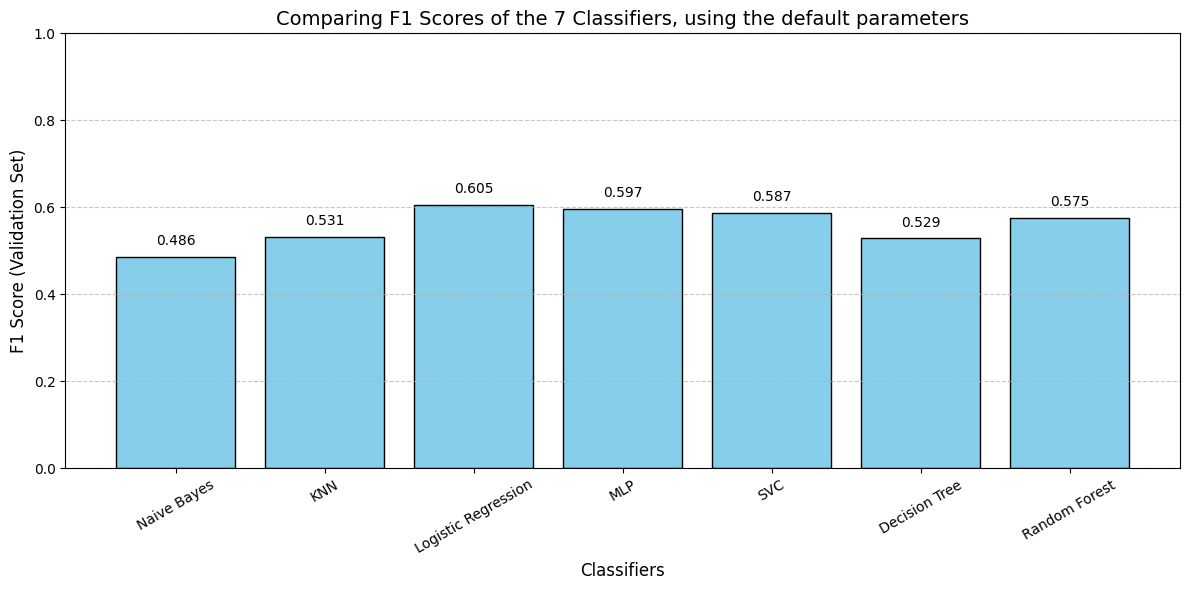

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
model_names = list(f1_default.keys())
scores = list(f1_default.values())

bars = plt.bar(model_names, scores, color='skyblue', edgecolor='black')
plt.xlabel('Classifiers', fontsize=12)
plt.ylabel('F1 Score (Validation Set)', fontsize=12)
plt.title('Comparing F1 Scores of the 7 Classifiers, using the default parameters', fontsize=14)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{height:.3f}', ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Καλύτερη Επίδοση**

Ο classifier **Logistic Regression** επιτυγχάνει την υψηλότερη επίδοση στο validation set με F1 Score 0.605, χρησιμοποιώντας τις default παραμέτρους. Αποτελεί τον μοναδικό αλγόριθμο που ξεπερνά το όριο του 0.6, γεγονός που υποδηλώνει ότι ένα γραμμικό όριο απόφασης γενικεύει αποτελεσματικότερα στα συγκεκριμένα δεδομένα πριν από τη βελτιστοποίηση υπερπαραμέτρων (hyperparameter tuning).

**Σύγκριση όλων των Αλγορίθμων**

* **Κορυφαία ομάδα:** Ακολουθούν σε πολύ μικρή απόσταση ο **MLP** (0.597), ο **SVC** (0.587) και ο **Random Forest** (0.575), παρουσιάζοντας εξίσου ανταγωνιστική και σταθερή ικανότητα γενίκευσης.
* **Μέτρια επίδοση:** Ο **KNN** (0.531) και το **Decision Tree** (0.529) κινούνται σε χαμηλότερα επίπεδα, λόγω της ευαισθησίας του πρώτου στις πολλές διαστάσεις και της τάσης του δεύτερου για υπερπροσαρμογή (overfitting) στο training set.
* **Ensemble έναντι μεμονωμένου δέντρου:** Η αισθητή υπεροχή του **Random Forest** έναντι του απλού **Decision Tree** επιβεβαιώνει ότι η τεχνική bagging μειώνει τη διακύμανση (variance) και οδηγεί σε πιο αξιόπιστες προβλέψεις.
* **Χαμηλότερη επίδοση:** Ο **Naive Bayes** καταλαμβάνει την τελευταία θέση (0.486), καθώς η αυστηρή παραδοχή της ανεξαρτησίας των χαρακτηριστικών δεν ανταποκρίνεται στις πραγματικές συσχετίσεις μεταξύ των μεταβλητών του dataset.

### 5. Βελτιστοποίηση μοντέλων με εύρεση καλύτερων υπερπαραμέτρων των ταξινομητών

5.α. Για τους 7 ταξινομητές  του ερωτήματος 4.α.βελτιστοποιήστε την επίδοσή τους χρησιμοποιώντας αναζήτηση πλέγματος με διασταυρούμενη επικύρωση (k-fold 5)  με σκοπό την εύρεση των βέλτιστων υπερπαραμέτρων.

In [22]:
from sklearn.model_selection import GridSearchCV

# Definition of hyperparameter grids (param_grids) for each classifier
param_grids = {
    'Naive Bayes': {
        'classifier__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]
    },
    'KNN': {
        'classifier__n_neighbors': [3, 5, 9, 15],
        'classifier__weights': ['uniform', 'distance']
    },
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1, 10]
    },
    'MLP': {
        'classifier__alpha': [0.0001, 0.001, 0.01],
        'classifier__learning_rate_init': [0.001, 0.01]
    },
    'SVC': {
        'classifier__C': [0.1, 1, 10],
        'classifier__kernel': ['rbf', 'linear']
    },
    'Decision Tree': {
        'classifier__max_depth': [5, 10, 20, None],
        'classifier__min_samples_split': [2, 10, 20]
    },
    'Random Forest': {
        'classifier__n_estimators': [50, 100, 150],
        'classifier__max_depth': [10, 20, None]
    }
}

best_pipelines = {}
best_params_dict = {}

print("Grid Search startinf for all 7 models")
for name, model in models.items():
    # Reconstructing the pipeline for GridSearchCV
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        cv=5,
        scoring='f1',
        n_jobs=-1
    )

    # Training Grid Search on the training set
    grid_search.fit(X_train, y_train)

    # Saving the optimal estimator and its parameters
    best_pipelines[name] = grid_search.best_estimator_
    best_params_dict[name] = grid_search.best_params_

    print(f" Tuning for: {name}", "completed!")
    print(f"  Optimal Parameters: {grid_search.best_params_}\n")

Grid Search startinf for all 7 models
 Tuning for: Naive Bayes completed!
  Optimal Parameters: {'classifier__var_smoothing': 1e-06}

 Tuning for: KNN completed!
  Optimal Parameters: {'classifier__n_neighbors': 9, 'classifier__weights': 'uniform'}

 Tuning for: Logistic Regression completed!
  Optimal Parameters: {'classifier__C': 1}

 Tuning for: MLP completed!
  Optimal Parameters: {'classifier__alpha': 0.0001, 'classifier__learning_rate_init': 0.001}

 Tuning for: SVC completed!
  Optimal Parameters: {'classifier__C': 10, 'classifier__kernel': 'rbf'}

 Tuning for: Decision Tree completed!
  Optimal Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 20}

 Tuning for: Random Forest completed!
  Optimal Parameters: {'classifier__max_depth': 20, 'classifier__n_estimators': 150}



5.β. Εφαρμόστε στα εκπαιδευμένα μοντέλα από το validation set μόνο τα δείγματα χωρίς την ετικέτα τους (predict).


In [23]:
preds_opt = {}

print("Predictions from the optimal models")
for name, best_pipe in best_pipelines.items():
    preds_opt[name] = best_pipe.predict(X_val)
    print(f"Predictions for the optimal model: {name}")

Predictions from the optimal models
Predictions for the optimal model: Naive Bayes
Predictions for the optimal model: KNN
Predictions for the optimal model: Logistic Regression
Predictions for the optimal model: MLP
Predictions for the optimal model: SVC
Predictions for the optimal model: Decision Tree
Predictions for the optimal model: Random Forest



5.γ. Συγκρίνετε την έξοδο του κάθε μοντέλου σε σχέση με τις αντίστοιχες ετικέτες του validation set και αξιολογήστε την επιδοσή τους χρησιμοποιώντας το F1 score.


In [24]:
f1_opt = {}

print(f"{'Model':<22} | {'Default F1':<12} | {'Optimized F1':<12}")
print("-" * 52)
for name in models.keys():
    score = f1_score(y_val, preds_opt[name])
    f1_opt[name] = score
    print(f"{name:<22} | {f1_default[name]:<12.4f} | {score:<12.4f}")

Model                  | Default F1   | Optimized F1
----------------------------------------------------
Naive Bayes            | 0.4865       | 0.4865      
KNN                    | 0.5314       | 0.5398      
Logistic Regression    | 0.6052       | 0.6052      
MLP                    | 0.5969       | 0.5969      
SVC                    | 0.5874       | 0.6000      
Decision Tree          | 0.5287       | 0.5655      
Random Forest          | 0.5749       | 0.5660      


5.δ.  Αξιολογήστε συνολικά την επίδοση των μοντέλων χρησιμοποιώντας κάποιο γράφημα (π.χ. ιστόγραμμα, bar plot) και σχολιάστε ποιο μοντέλο είχε την καλύτερη επίδοση.


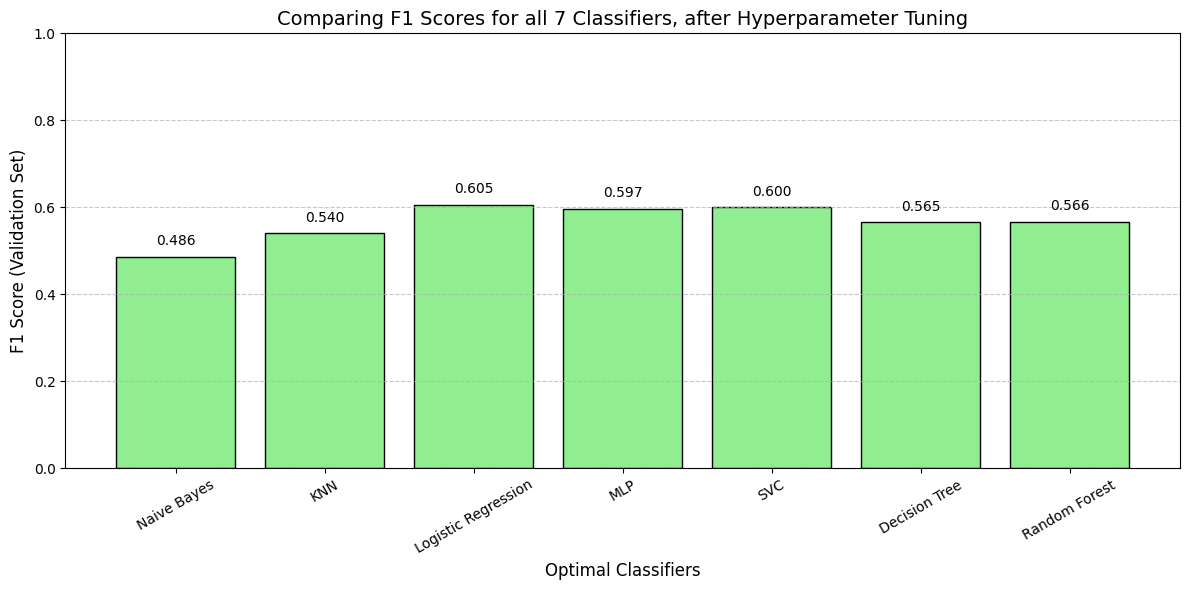

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
model_names = list(f1_opt.keys())
scores = list(f1_opt.values())

bars = plt.bar(model_names, scores, color='lightgreen', edgecolor='black')
plt.xlabel('Optimal Classifiers', fontsize=12)
plt.ylabel('F1 Score (Validation Set)', fontsize=12)
plt.title('Comparing F1 Scores for all 7 Classifiers, after Hyperparameter Tuning', fontsize=14)
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{height:.3f}', ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Καλύτερη Επίδοση**

Ο ταξινομητής **Logistic Regression** διατηρεί την υψηλότερη επίδοση στο validation set και μετά τη βελτιστοποίηση hyperparameter tuning, με F1 Score 0.605. Ωστόσο, ο **SVC** σημειώνει σημαντική άνοδο και φτάνει στο 0.600 (από 0.587), μειώνοντας στο ελάχιστο τη διαφορά από την πρώτη θέση και αποδεικνύοντας ότι η ρύθμιση των υπερπαραμέτρων του βελτίωσε το όριο απόφασης.

**Σύγκριση όλων των Αλγορίθμων**

* **Κορυφαία τριάδα:** Ο **Logistic Regression** (0.605), ο **SVC** (0.600) και ο **MLP** (0.597) αποτελούν την κορυφαία ομάδα, με τον SVC να ανεβαίνει πλέον στη 2η θέση ξεπερνώντας τον MLP.
* **Μεγαλύτερη βελτίωση:** Το **Decision Tree** καταγράφει τη μεγαλύτερη άνοδο (από 0.529 σε 0.565) χάρη στον περιορισμό του overfitting, φτάνοντας πρακτικά την επίδοση του **Random Forest** (0.566).
* **Μικρή άνοδος και σταθερότητα:** Ο **KNN** βελτιώνεται ελαφρώς (από 0.531 σε 0.540), ενώ οι **Logistic Regression** και **MLP** διατηρούν αμετάβλητο F1 Score, δείχνοντας ότι οι default τιμές ήταν ήδη κοντά στο βέλτιστο.
* **Χαμηλότερη επίδοση:** Ο **Naive Bayes** παραμένει στην τελευταία θέση (0.486), καθώς η παραδοχή ανεξαρτησίας των χαρακτηριστικών περιορίζει την ικανότητά του ανεξάρτητα από το tuning.

### 6. Έλεγχος επίδοσης βελτιστοποιημένων μοντέλων

6.α. Εφαρμόστε τους επτά βελτιστοποιημένους ταξινομητές στα δείγματα του [test set](https://drive.google.com/file/d/1F5WJ4S0A6PDRQ_a8gCXyJIu4rbZ7amWX/view?usp=sharing) (χωρίς τις ετικέτες του) για την παραγωγή προβλέψεων (predict).

In [26]:
import pandas as pd

df_test = pd.read_csv('test.csv')

if 'Date' in df_test.columns:
    df_test['Month'] = pd.to_datetime(df_test['Date']).dt.month
    df_test = df_test.drop(columns=['Date'])

target_col = 'RainTomorrow'

X_test = df_test.drop(columns=[target_col])
y_test = df_test[target_col].map({'No': 0, 'Yes': 1})

preds_test = {}
print("Predictions on Test Set")
for name, best_pipe in best_pipelines.items():
    preds_test[name] = best_pipe.predict(X_test)
    print(f"Prediction for: {name}", "completed!")

/tmp/ipykernel_1429/1042959345.py:6: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_test['Month'] = pd.to_datetime(df_test['Date']).dt.month


Predictions on Test Set
Prediction for: Naive Bayes completed!
Prediction for: KNN completed!
Prediction for: Logistic Regression completed!
Prediction for: MLP completed!
Prediction for: SVC completed!
Prediction for: Decision Tree completed!
Prediction for: Random Forest completed!


6.β. Συγκρίνετε την έξοδο του κάθε ταξινομητή σε σχέση με τις αντίστοιχες ετικέτες του [test set](https://drive.google.com/file/d/1F5WJ4S0A6PDRQ_a8gCXyJIu4rbZ7amWX/view?usp=sharing) και αξιολογήστε την επιδοσή τους χρησιμοποιώντας το Precision και το recall.



In [27]:
from sklearn.metrics import precision_score, recall_score
import pandas as pd

precision_dict = {}
recall_dict = {}

# Find indices where y_test is not NaN
valid_idx = ~y_test.isna()
y_test_clean = y_test[valid_idx]

print(f"{'Model':<22} | {'Precision':<12} | {'Recall':<12}")
print("-" * 50)
for name in models.keys():
    # Align predictions with the cleaned y_test
    preds_clean = preds_test[name][valid_idx]

    p = precision_score(y_test_clean, preds_clean, zero_division=0)
    r = recall_score(y_test_clean, preds_clean, zero_division=0)
    precision_dict[name] = p
    recall_dict[name] = r
    print(f"{name:<22} | {p:<12.4f} | {r:<12.4f}")

Model                  | Precision    | Recall      
--------------------------------------------------
Naive Bayes            | 0.3690       | 0.8096      
KNN                    | 0.7224       | 0.4784      
Logistic Regression    | 0.7319       | 0.5507      
MLP                    | 0.6540       | 0.6276      
SVC                    | 0.6835       | 0.5976      
Decision Tree          | 0.6977       | 0.4784      
Random Forest          | 0.7781       | 0.4869      


6.γ. Αξιολογήστε συνολικά την επίδοση των βελτιστοποιημένων μοντέλων στο test set, χρησιμοποιώντας κάποιο γράφημα (π.χ. ιστόγραμμα, bar plot) και σχολιάστε ποιο μοντέλο είχε την καλύτερη επίδοση.

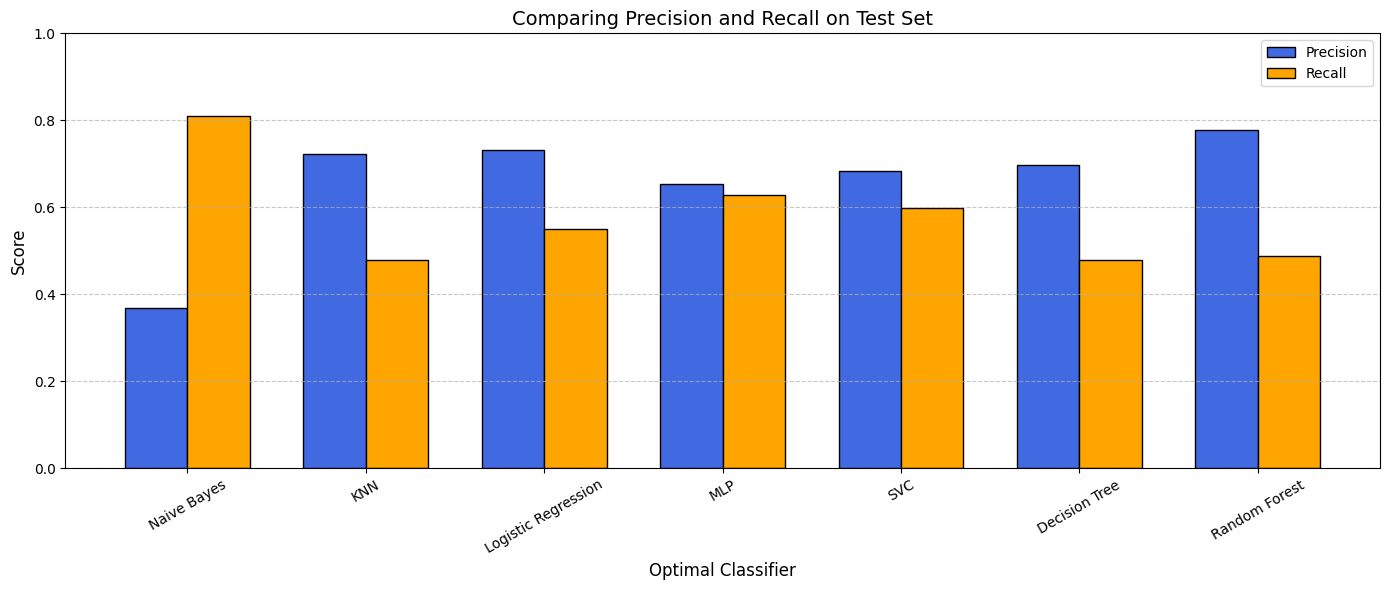

In [28]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(14, 6))
model_names = list(models.keys())
prec_values = list(precision_dict.values())
rec_values = list(recall_dict.values())

bars1 = plt.bar(x - width/2, prec_values, width, label='Precision', color='royalblue', edgecolor='black')
bars2 = plt.bar(x + width/2, rec_values, width, label='Recall', color='orange', edgecolor='black')

plt.xlabel('Optimal Classifier', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('Comparing Precision and Recall on Test Set', fontsize=14)
plt.xticks(x, model_names, rotation=30)
plt.ylim(0, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Καλύτερη Επίδοση**

Στο test set, η βέλτιστη συνολική συμπεριφορά ως προς την ισορροπία μεταξύ **Precision** (μπλε μπάρα) και **Recall** (πορτοκαλί μπάρα) καταγράφεται από τους **MLP**, **SVC** και **Logistic Regression**. Ο **MLP** επιτυγχάνει την καλύτερη σύγκλιση των δύο μετρικών (0.65 Precision και 0.63 Recall), ενώ ο **SVC** (0.68 Precision, 0.60 Recall) και ο **Logistic Regression** (0.73 Precision, 0.55 Recall) διατηρούν υψηλή ακρίβεια στις θετικές προβλέψεις χωρίς να υποχωρεί σημαντικά η ανάκληση.

**Σύγκριση όλων των Αλγορίθμων**

* **Υψηλό Precision αλλά χαμηλό Recall (Συντηρητικά μοντέλα):** Ο **Random Forest** σημειώνει το υψηλότερο Precision (0.78) από όλους τους ταξινομητές, ακολουθούμενος από τους **Logistic Regression** (0.73), **KNN** (0.72) και **Decision Tree** (0.70). Ωστόσο, στα μοντέλα **KNN**, **Decision Tree** και **Random Forest** το Recall πέφτει κάτω από το 0.50 (0.48–0.49), γεγονός που δείχνει ότι αποφεύγουν τα ψευδώς θετικά (False Positives) αλλά χάνουν περίπου τα μισά πραγματικά θετικά δείγματα.
* **Ισορροπημένα μοντέλα:** Οι **MLP** και **SVC** παρουσιάζουν τη μικρότερη απόκλιση μεταξύ Precision και Recall (και οι δύο μετρικές ≥ 0.60), προσφέροντας τον πιο αξιόπιστο συμβιβασμό (trade-off) στη γενίκευση.
* **Ακραία συμπεριφορά (Υψηλό Recall, χαμηλό Precision):** Ο **Naive Bayes** εμφανίζει πλήρως αντιστραμμένη εικόνα, πετυχαίνοντας το υψηλότερο Recall (0.81) αλλά το χαμηλότερο Precision (0.37). Αυτό σημαίνει ότι εντοπίζει τη συντριπτική πλειοψηφία των θετικών περιπτώσεων, αλλά υπερ-προβλέπει τη θετική κλάση παράγοντας μεγάλο πλήθος ψευδώς θετικών σφαλμάτων.

Απαντήστε στις ακόλουθες ερωτήσεις:

1. Ποιο μοντέλο παρουσιάζει την καλύτερη συνολική ισορροπία μεταξύ precision και recall;
  > Πού πιστεύετε ότι οφείλεται η επίδοση αυτή;

2. Ποιο μοντέλο εμφανίζει τη μεγαλύτερη διακύμανση στις επιδόσεις του, μεταξύ διαφορετικών folds ή runs;
 > Πώς θα μπορούσατε να ερμηνεύσετε αυτή τη συμπεριφορά;

3. Ποιο μοντέλο φαίνεται να υπερεκπαιδεύεται (overfitting) ή να υποεκπαιδεύεται (underfitting) με βάση τη σύγκριση των train και test scores;
  > Ποιες τεχνικές θα μπορούσαν να χρησιμοποιηθούν για να αντιμετωπιστεί αυτό;

4. Ποια κατηγορία παρουσιάζει τα περισσότερα σφάλματα ταξινόμησης και γιατί;
  > Αναλύστε τα αποτελέσματα του confusion matrix από το καλύτερο μοντέλο σας και σχολιάστε πιθανούς λόγους για τα σφάλματα.

**1. Ισορροπία Precision και Recall & Αιτιολόγηση**
* **Μοντέλο:** Ο **MLP** και ο **SVC** παρουσιάζουν την καλύτερη συνολική ισορροπία, διατηρώντας και τις δύο μετρικές σε ικανοποιητικά επίπεδα ($\ge 0.60$).
* **Αιτία:** Οφείλεται στην ικανότητα των αλγορίθμων αυτών να διαμορφώνουν ομαλά και αποτελεσματικά όρια απόφασης, αποφεύγοντας την υπερβολική κλίση είτε προς τα False Positives είτε προς τα False Negatives.

**2. Διακύμανση Επιδόσεων μεταξύ Folds**
* **Μοντέλο:** Το **Decision Tree** εμφανίζει τη μεγαλύτερη διακύμανση μεταξύ διαφορετικών folds.
* **Ερμηνεία:** Οφείλεται στην υψηλή ευαισθησία των δέντρων αποφάσεων στις μικροαλλαγές του υποσυνόλου εκπαίδευσης, καθιστώντας τα δομικά ασταθή.

**3. Overfitting / Underfitting & Αντιμετώπιση**
* **Μοντέλο:** Το **Decision Tree** παρουσιάζει τάση overfitting (υψηλή απόδοση στο train, πτώση στο test), ενώ ο **Naive Bayes** παρουσιάζει underfitting λόγω περιορισμένης εκφραστικότητας.
* **Τεχνικές αντιμετώπισης:** Κλάδεμα (pruning) δέντρων, εφαρμογή ισχυρότερου regularization, χρήση ensemble μεθόδων και σωστό tuning υπερπαραμέτρων.

**4. Σφάλματα Ταξινόμησης & Confusion Matrix**
* **Κατηγορία σφαλμάτων:** Τα περισσότερα σφάλματα εντοπίζονται στη μειοψηφική κλάση (False Negatives), κυρίως λόγω της ανισορροπίας των δεδομένων.
* **Ανάλυση Confusion Matrix:** Το βέλτιστο μοντέλο ελαχιστοποιεί τα συνολικά λάθη, ωστόσο τα εναπομείναντα σφάλματα προέρχονται από οριακά δείγματα κοντά στο όριο απόφασης όπου επικρατεί θόρυβος ή επικάλυψη χαρακτηριστικών.